#**Laboratorio 2: Simulación e Inferencia — Airbnb Nueva York**  
INF280 Estadística Computacional, UTFSM — Grupo 25  
Integrantes: José Flores, Sebastian Alcaide, Pedro Ortiz y Miguel Primera

In [16]:
import kagglehub
import pandas as pd
import numpy as np

# Fijamos semilla para reproducibilidad
RANDOM_STATE = 2026
np.random.seed(RANDOM_STATE)

# Descarga del dataset
path = kagglehub.dataset_download("arianazmoudeh/airbnbopendata")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'airbnbopendata' dataset.
Path to dataset files: /kaggle/input/airbnbopendata


In [17]:
# Limpieza del entregable anterior
df = pd.read_csv(f"{path}/Airbnb_Open_Data.csv")
df = df.drop_duplicates()
df['neighbourhood group'] = df['neighbourhood group'].replace({
    'manhatan': 'Manhattan',
    'brookln': 'Brooklyn'
})
for col in ['price', 'service fee']:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(df[col], errors='coerce')
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df = df.drop(columns=['license', 'house_rules', 'country', 'country_code'])
df.loc[(df['availability_365'] < 0) | (df['availability_365'] > 365), 'availability_365'] = np.nan
df.loc[df['minimum_nights'] < 0, 'minimum_nights'] = np.nan

/tmp/ipykernel_1604/1478156835.py:2: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{path}/Airbnb_Open_Data.csv")


In [18]:
pares = df[['neighbourhood_group', 'review_rate_number']].dropna()
M = pares.loc[pares['neighbourhood_group'] == 'Manhattan', 'review_rate_number'].to_numpy()
K = pares.loc[pares['neighbourhood_group'] == 'Brooklyn', 'review_rate_number'].to_numpy()

# Mostrar conteos
print('Filas sin duplicados y limpiadas:', len(df), '| con distrito y nota:', len(pares))
print('Manhattan:', len(M), 'anuncios | Brooklyn:', len(K), 'anuncios')

Filas sin duplicados y limpiadas: 102058 | con distrito y nota: 101712
Manhattan: 43418 anuncios | Brooklyn: 41515 anuncios


##1. Parámetros de interés y conexión con la Entrega 1

En la Entrega 1 por medio del ANOVA obtuvimos que la calificación media varía entre distritos. Aquí cuantificamos el contraste entre los dos distritos con más anuncios. Los parámetros son:

$$\mu_M: \text{media de calificaciones en Manhattan.}$$
$$\mu_B: \text{media de calificaciones en Brooklyn.}$$
$$\Delta = \mu_M - \mu_B$$

Estos parámetros son pertinentes debido a que cambiamos el enfoque desde si hay diferencias; pregunta de investigación en la entrega 1; a preguntarnos de qué tamaño es esta diferencia y qué tan precisa es su estimación.

##2. Estimación puntual

Estimadores:  
$$\hat\mu_M: \text{estimación de la media de calificaciones en Manhattan.}$$
$$\hat\mu_B: \text{estimación de la media de calificaciones en Brooklyn.}$$
$$\hat\Delta: \text{estimación de la diferencia de medias.}$$

Además consideramos la estimación de los errores estandar (EE) de cada parámetro para posteriormente concluir en base a ellos.

$$\widehat{EE}(\bar Y_M)=\frac{s_M}{\sqrt{n_M}},\quad \widehat{EE}(\bar Y_B)=\frac{s_B}{\sqrt{n_B}},\qquad \widehat{EE}(\hat\Delta)=\sqrt{\frac{s_M^2}{n_M}+\frac{s_B^2}{n_B}}$$

$\bar Y: \text{media de calificaciones de un distrito desde la muestra original.}$  
$\ s: \text{desviación estandar de calificaciones en un distrito}$  
$\ n: \text{número de anuncios en un distrito}$

Propiedades: la media muestral es insesgada $E(\bar Y)=\mu$, consistente, ya que converge a $\mu$ cuando $n$ crece y eficiente entre los estimadores lineales insesgados. Esto supone observaciones independientes y una muestra representativa del parámetro objetivo.

In [19]:
def resumen_media(x):
    n = len(x)
    media = x.mean()
    ee = x.std(ddof=1) / np.sqrt(n)
    return media, ee

mu_m, ee_m = resumen_media(M)
mu_b, ee_b = resumen_media(K)

delta = mu_m - mu_b
ee_delta = np.sqrt(ee_m**2 + ee_b**2)

clasico = pd.DataFrame({'estimacion': [mu_m, mu_b, delta],
                        'EE': [ee_m, ee_b, ee_delta]},
                       index=['Media Manhattan', 'Media Brooklyn', 'Diferencia M-B'])
clasico.round(4)

,estimacion,EE
Media Manhattan,3.2765,0.0062
Media Brooklyn,3.2585,0.0064
Diferencia M-B,0.0181,0.0089


#3. Bootstrap
## 3.1 Origen, motivación y relevancia
Lo propuso Bradley Efron en 1979. Idea: la muestra que tenemos es nuestra mejor aproximación de la población, así que remuestreamos desde ella para ver cuánto variaría un estimador si repitiéramos el muestreo. Sirve cuando no hay (o es difícil obtener) una fórmula para el error de un estadístico, como una mediana, un cuantil o un coeficiente de regresión. Hoy es una herramienta estándar para obtener errores estándar e intervalos con poco supuesto distribucional.

## 3.2 Pasos del procedimiento
1. Calcular el estimador en la muestra original.  
2. Sortear con reemplazo una remuestra del mismo tamaño que la original (en cada distrito por separado).  
3. Calcular el estimador en la remuestra.  
4. Repetir los pasos 2 y 3 veces.  
5. Usar la desviación estándar de las réplicas como EE.  
  
Ejemplo: si los datos son [1, 3, 5], una remuestra posible es [5, 5, 1]: mismo tamaño, un dato repetido y otro ausente.

In [20]:
B = 10_000
SEED = RANDOM_STATE

def bootstrap(x, y, B, rng):
    res = np.empty((B, 3))
    for b in range(B):
        xb = x[rng.integers(0, len(x), len(x))]   # sorteo con reemplazo, mismo tamaño
        yb = y[rng.integers(0, len(y), len(y))]
        res[b] = xb.mean(), yb.mean(), xb.mean() - yb.mean()
    return res

boot = bootstrap(M, K, B, np.random.default_rng(SEED))

boot_tabla = pd.DataFrame({
    'estimacion': [mu_m, mu_b, delta],
    'EE': boot.std(axis=0, ddof=1)
}, index=clasico.index)

boot_tabla.round(4)

,estimacion,EE
Media Manhattan,3.2765,0.0062
Media Brooklyn,3.2585,0.0063
Diferencia M-B,0.0181,0.0088


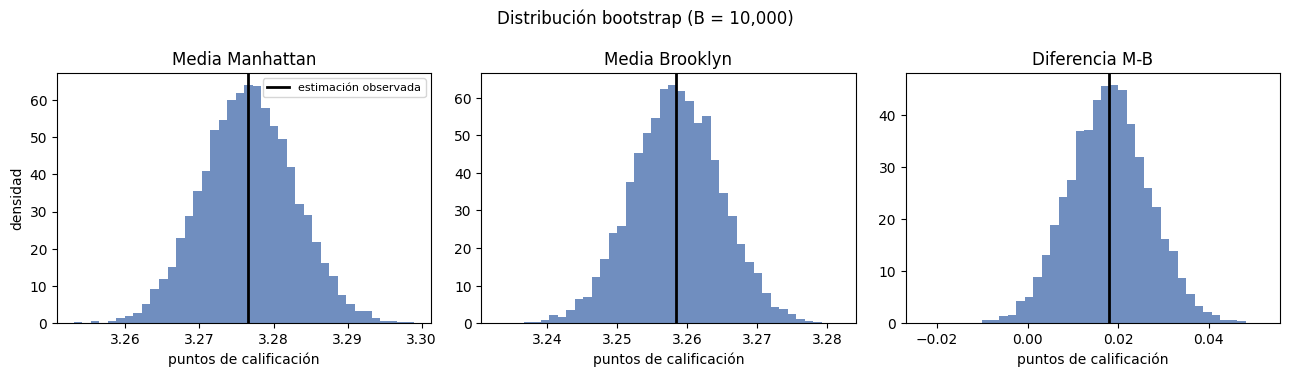

In [21]:
import matplotlib.pyplot as plt

# 5. Distribución de los estadísticos bootstrap
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for j, (ax, nombre) in enumerate(zip(axes, clasico.index)):
    # Histograma de las réplicas bootstrap
    ax.hist(boot[:, j], bins=40, density=True, color='#4c72b0', alpha=0.8)

    # Línea vertical para la estimación observada
    ax.axvline(clasico.iloc[j]['estimacion'], color='k', lw=2, label='estimación observada')

    ax.set_title(nombre)
    ax.set_xlabel('puntos de calificación')

axes[0].set_ylabel('densidad')
axes[0].legend(fontsize=8)
fig.suptitle(f'Distribución bootstrap (B = {B:,})')
fig.tight_layout()
plt.show()

## 3.3 Comparación con la estimación clásica

In [22]:
# 6. Clásico vs bootstrap, y estabilidad según cantidad de repeticiones
comp = pd.DataFrame({
    'EE_clasico': clasico['EE'],
    'EE_bootstrap': boot_tabla['EE']
})
comp['razon_boot/clasico'] = comp['EE_bootstrap'] / comp['EE_clasico']
display(comp.round(5))

# Estabilidad: EE bootstrap de la diferencia usando las primeras b réplicas
estab = pd.DataFrame({
    'B': [200, 1000, 5000, B],
    'EE_diferencia': [boot[:b, 2].std(ddof=1) for b in [200, 1000, 5000, B]]
})
display(estab.round(5))

,EE_clasico,EE_bootstrap,razon_boot/clasico
Media Manhattan,0.00619,0.00623,1.00591
Media Brooklyn,0.00636,0.00630,0.99133
Diferencia M-B,0.00888,0.00883,0.99481


,B,EE_diferencia
0,200,0.00911
1,1000,0.00887
2,5000,0.00870
3,10000,0.00883


¿Hay diferencias relevantes entre ambos enfoques? No, ya que los EE casi coinciden. Esto es esperable, debido a que el estimador es una media y las muestras son muy grandes.

Ventajas del bootstrap: muestra la distribución completa del estimador, no exige fórmula ni normalidad, y se extiende a estadísticos sin fórmula simple.  
  
Limitaciones: depende de que la muestra sea representativa y de observaciones independientes; el resultado tiene un pequeño error numérico por usar $B$ finito, que se estabiliza al aumentar $B$; y requiere más cómputo que la fórmula.